# Gaussian flow-matching curvature baseline

Select the project environment (`uv sync --locked --extra notebook`). 

We integrate exact **marginal** velocity fields, not conditional training interpolants. The latter are straight for both couplings. Population OT should have near-zero geometric bending, whereas independent coupling generally does not. This isolates geometry from neural approximation error.

In [1]:
import numpy as np
from flow_curvature import GaussianPair, sample_endpoints, gaussian_velocity, integrate, trajectory_diagnostics
from flow_curvature.diagnostics import summarize
from flow_curvature.plotting import plot_trajectories

pair = GaussianPair()
initial, _ = sample_endpoints(pair, 256, seed=42)
times = np.linspace(0, 1, 201)
paths = {name: integrate(gaussian_velocity(pair, name), initial, times)
         for name in ('independent', 'ot')}
metrics = {name: trajectory_diagnostics(path, times) for name, path in paths.items()}
{name: summarize(values) for name, values in metrics.items()}

{'independent': {'bending_energy': {'mean': 6.740466226681049,
   'median': 0.3509067587148469,
   'p95': 7.042695604116393},
  'mean_curvature': {'mean': 0.38561402253326726,
   'median': 0.3263627928550261,
   'p95': 0.857770149578843},
  'acceleration_energy': {'mean': 11.524461243432796,
   'median': 6.966414321817564,
   'p95': 36.03482149567863},
  'path_length': {'mean': 2.4767676616849705,
   'median': 2.4264756160233167,
   'p95': 3.40337692663166},
  'chord_length': {'mean': 2.3631840686478,
   'median': 2.3260069756551602,
   'p95': 3.2082794477717522},
  'length_excess': {'mean': 0.11358359303717083,
   'median': 0.06381783551782805,
   'p95': 0.4154538966520921},
  'stationary_fraction': {'mean': 0.0, 'median': 0.0, 'p95': 0.0}},
 'ot': {'bending_energy': {'mean': 1.7117344478155678e-25,
   'median': 5.859614879815985e-26,
   'p95': 6.071169101179107e-25},
  'mean_curvature': {'mean': 7.650455364850878e-14,
   'median': 5.16996308282092e-14,
   'p95': 2.0138622410518948e-1

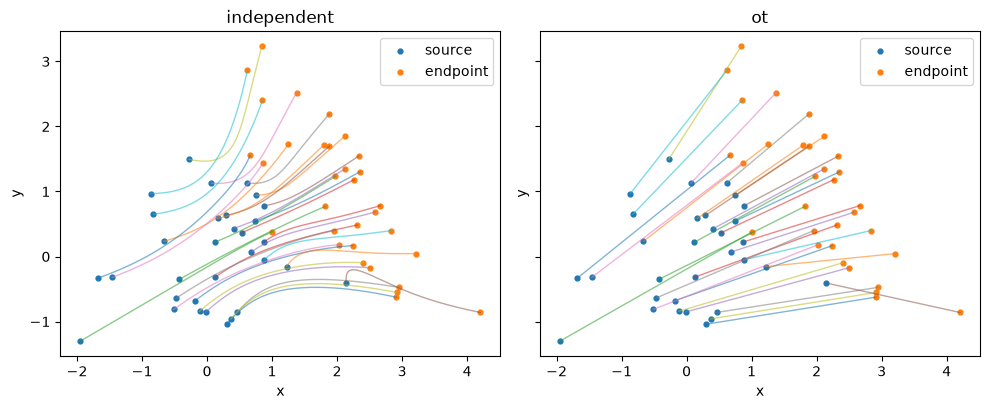

In [4]:
figure = plot_trajectories(paths)

In [3]:
assert metrics['ot']['bending_energy'].max() < 1e-16
assert metrics['independent']['bending_energy'].mean() > 0.01
np.testing.assert_allclose(paths['ot'][-1], pair.transport(initial), atol=1e-10)

# Check discretization sensitivity using identical evaluation points.
fine_times = np.linspace(0, 1, 401)
fine_paths = integrate(gaussian_velocity(pair, 'independent'), initial, fine_times)
fine_metrics = trajectory_diagnostics(fine_paths, fine_times)
{'coarse': metrics['independent']['bending_energy'].mean(),
 'fine': fine_metrics['bending_energy'].mean()}

{'coarse': np.float64(6.740466226681049),
 'fine': np.float64(6.740931536286252)}

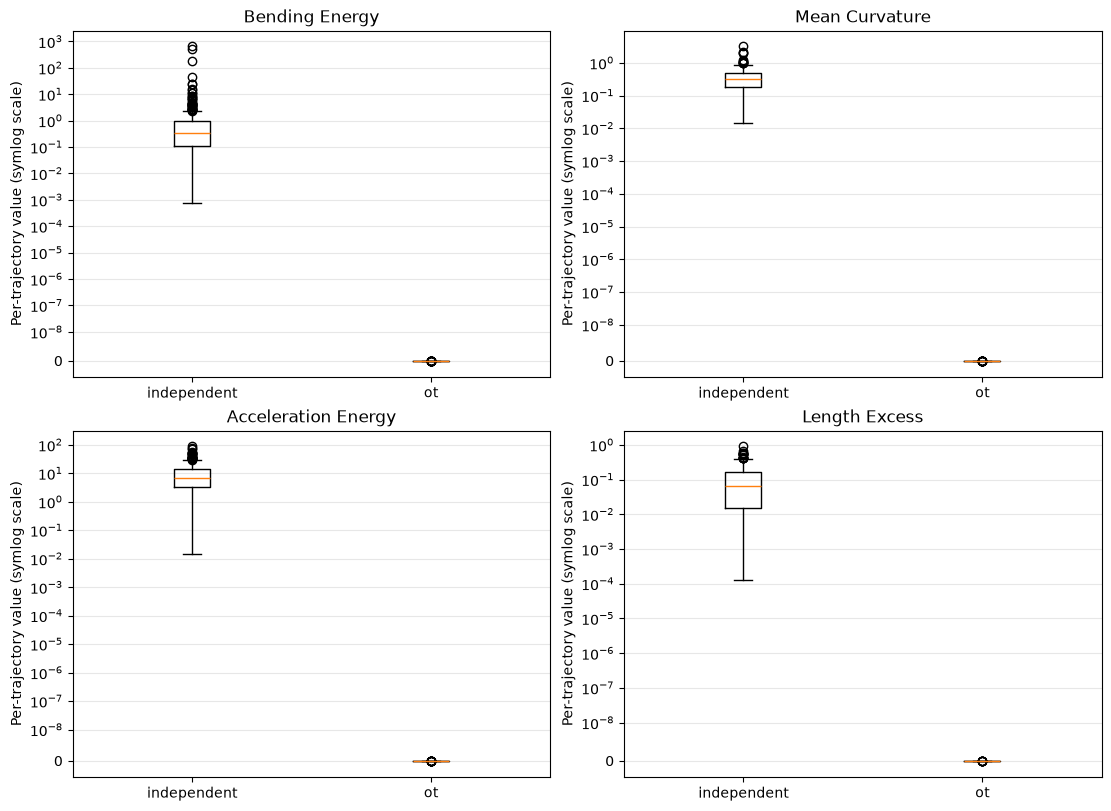

In [5]:
import matplotlib.pyplot as plt

methods = list(metrics)
selected = [
    "bending_energy",
    "mean_curvature",
    "acceleration_energy",
    "length_excess",
]

fig, axes = plt.subplots(
    2, 2, figsize=(11, 8), constrained_layout=True
)

for ax, key in zip(axes.flat, selected):
    ax.boxplot(
        [metrics[method][key] for method in methods],
        tick_labels=methods,
        showfliers=True,
    )
    ax.set_yscale("symlog", linthresh=1e-8)
    ax.set_title(key.replace("_", " ").title())
    ax.set_ylabel("Per-trajectory value (symlog scale)")
    ax.grid(axis="y", alpha=0.3)

plt.show()

In [6]:
from IPython.display import Markdown, display
from flow_curvature.diagnostics import summarize

summaries = {
    method: summarize(values)
    for method, values in metrics.items()
}

rows = [
    "| Method | Diagnostic | Mean | Median | P95 |",
    "|---|---|---:|---:|---:|",
]

for method, diagnostics in summaries.items():
    for key, stats in diagnostics.items():
        rows.append(
            f"| {method} | {key} "
            f"| {stats['mean']:.3e} "
            f"| {stats['median']:.3e} "
            f"| {stats['p95']:.3e} |"
        )

display(Markdown("\n".join(rows)))

| Method | Diagnostic | Mean | Median | P95 |
|---|---|---:|---:|---:|
| independent | bending_energy | 6.740e+00 | 3.509e-01 | 7.043e+00 |
| independent | mean_curvature | 3.856e-01 | 3.264e-01 | 8.578e-01 |
| independent | acceleration_energy | 1.152e+01 | 6.966e+00 | 3.603e+01 |
| independent | path_length | 2.477e+00 | 2.426e+00 | 3.403e+00 |
| independent | chord_length | 2.363e+00 | 2.326e+00 | 3.208e+00 |
| independent | length_excess | 1.136e-01 | 6.382e-02 | 4.155e-01 |
| independent | stationary_fraction | 0.000e+00 | 0.000e+00 | 0.000e+00 |
| ot | bending_energy | 1.712e-25 | 5.860e-26 | 6.071e-25 |
| ot | mean_curvature | 7.650e-14 | 5.170e-14 | 2.014e-13 |
| ot | acceleration_energy | 1.289e-23 | 9.800e-24 | 3.045e-23 |
| ot | path_length | 2.363e+00 | 2.326e+00 | 3.208e+00 |
| ot | chord_length | 2.363e+00 | 2.326e+00 | 3.208e+00 |
| ot | length_excess | 2.429e-15 | 2.220e-16 | 9.326e-15 |
| ot | stationary_fraction | 0.000e+00 | 0.000e+00 | 0.000e+00 |

## Optional learned comparison

Run `uv sync --locked --extra notebook --extra neural`, then run the following in a new cell. Choose a new run directory on reruns (the runner refuses to overwrite results).

```python
from pathlib import Path
from flow_curvature.experiment import ExperimentConfig, run_experiment

# Locate the repository whether the kernel starts here or at its root.
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
report = run_experiment(
    ExperimentConfig(seed=42, train_steps=2000),
    output_dir=root / 'results' / 'neural-seed42',
    data_dir=root / 'data' / 'processed',
)
report['summary']
```

Finite-data minibatch OT and an approximate MLP need not recover straight trajectories. Compare endpoint quality as well as curvature; repeat seeds and refine the integration grid before drawing conclusions.